In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import tensorflow as tf
from tensorflow import keras 
from tensorflow.keras import losses
from tensorflow.keras import callbacks
from tensorflow.keras import layers
from tensorflow.keras import optimizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam , Adamax
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.layers import Conv2D, MaxPooling2D , GlobalAveragePooling2D,Dropout,BatchNormalization,Input,Flatten,Dense
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

In [29]:
base_dir = '/kaggle/input/datasets/salmansajid05/oral-diseases' 
output_dir = '/kaggle/working/Clean_Original_Data'

classes = ['Calculus', 'Caries', 'Gingivitis', 'Mouth Ulcer', 'Tooth Discoloration', 'hypodontia']

for cls in classes:
    dest_cls_dir = os.path.join(output_dir, cls)
    os.makedirs(dest_cls_dir, exist_ok=True)
    
    if cls == 'Caries':
        src_path = os.path.join(base_dir, 'Data caries', 'Data caries', 'caries orignal data set', 'done')
    elif cls == 'Mouth Ulcer':
        src_path = os.path.join(base_dir, 'Mouth Ulcer', 'Mouth Ulcer', 'ulcer original dataset', 'ulcer original dataset')
    elif cls == 'Tooth Discoloration':
        src_path = os.path.join(base_dir, 'Tooth Discoloration', 'Tooth Discoloration ', 'tooth discoloration original dataset', 'tooth discoloration original dataset')
    else:
        src_path = os.path.join(base_dir, cls, cls)
    
    if os.path.exists(src_path):
        for img_name in os.listdir(src_path):
            src_img = os.path.join(src_path, img_name)
            dest_img = os.path.join(dest_cls_dir, img_name)
            if os.path.isfile(src_img) and not os.path.exists(dest_img):
                shutil.copy(src_img, dest_img)

In [30]:
for cls in classes:
    path = os.path.join(output_dir, cls)
    print(cls, len(os.listdir(path)))

Calculus 1296
Caries 219
Gingivitis 2349
Mouth Ulcer 265
Tooth Discoloration 183
hypodontia 1251


# Load The Training and Validation Dataset

In [31]:
TrainPath    = '/kaggle/working/Clean_Original_Data'
batch_size   = 32
image_height = 224
image_width  = 224
epochs       = 200

train_ds = image_dataset_from_directory(
    TrainPath,
    labels='inferred',
    label_mode='int',
    validation_split=0.2,
    subset='training',
    seed=0,
    image_size=(image_height, image_width),
    batch_size=batch_size
)


validation_ds = image_dataset_from_directory(
    TrainPath,
    labels='inferred',
    label_mode='int',
    validation_split=0.2,
    subset='validation',
    seed=0,
    image_size=(image_height, image_width),
    batch_size=batch_size
)

Found 5563 files belonging to 6 classes.
Using 4451 files for training.
Found 5563 files belonging to 6 classes.
Using 1112 files for validation.


In [32]:
for images, labels in train_ds.take(1):# take first batch
        print("Images shape: ", images.shape)
        print("Labels shape: ", labels.shape)
        print("Labels : ", labels.numpy())

Images shape:  (32, 224, 224, 3)
Labels shape:  (32,)
Labels :  [0 2 2 2 3 2 2 2 0 5 0 0 2 5 2 2 2 2 2 2 0 2 2 5 0 2 0 2 0 0 5 2]


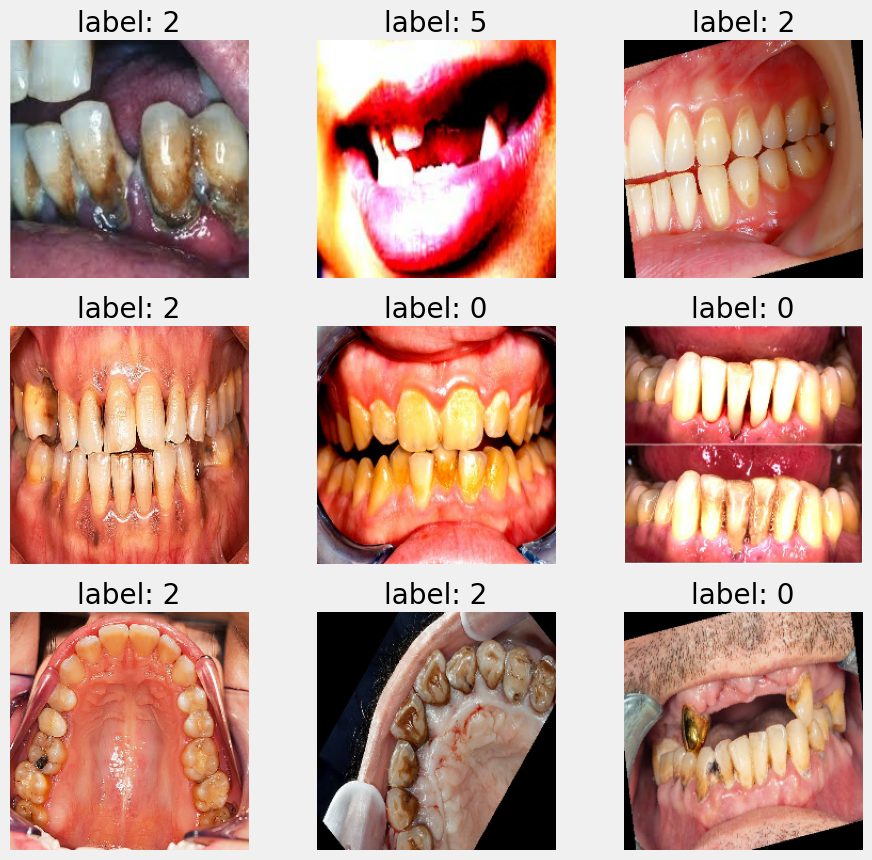

In [33]:
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10,10))
    for i in range(9):
           ax = plt.subplot(3,3,i+1)
           plt.imshow(images[i].numpy().astype("uint8"))
           plt.title(f"label: {labels[i].numpy()}")
           plt.axis("off")
           
    plt.show()

In [34]:
class_names = train_ds.class_names
print(class_names)

['Calculus', 'Caries', 'Gingivitis', 'Mouth Ulcer', 'Tooth Discoloration', 'hypodontia']


# Data Augmentation

In [35]:
img_augmentation = Sequential(
    [
        layers.RandomRotation(factor = 0.08),
        
        layers.RandomZoom(height_factor=(-0.1, 0.1), width_factor=(-0.1, 0.1)),
        
        layers.RandomTranslation(height_factor = 0.1,width_factor = 0.1),
        
        layers.RandomFlip("horizontal"),
        
        layers.RandomContrast(factor =0.1),
        layers.RandomBrightness(factor=0.1),
        
        layers.GaussianNoise(stddev =0.05),
    ],
    name = 'img_augmentation'
)

# View the Augmentation

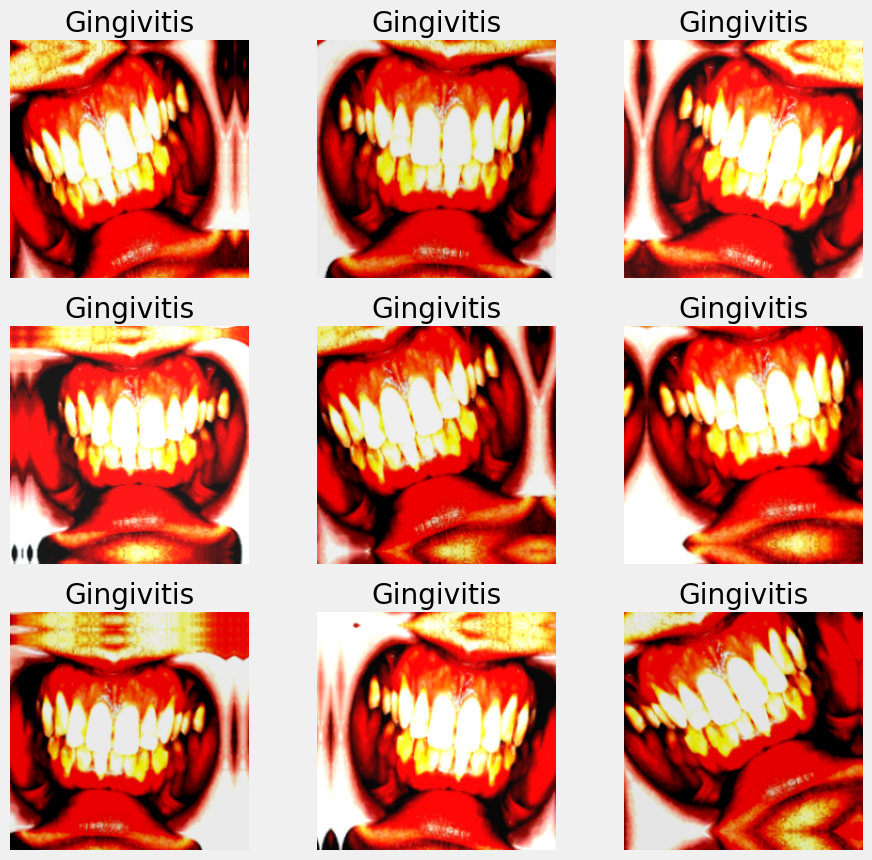

In [36]:
plt.figure(figsize=(10,10))

for image,labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3,3,i+1)
        aug_img = img_augmentation(tf.expand_dims(image[0],axis=0)) # (224,224,3) --->(1,224,224,3)
        plt.imshow(aug_img[0].numpy().astype('uint8'))
        plt.title(class_names[labels[0]])
        plt.axis('off')

# Catching & Prefetching (Optimizing)

In [37]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Models

# Define Callbacks

In [38]:
lr_callback   = callbacks.ReduceLROnPlateau(monitor= 'val_accuracy',factor = 0.1,patience=10)
stop_callback = callbacks.EarlyStopping(monitor= 'val_accuracy',patience=20)
model_ckpt = callbacks.ModelCheckpoint("cnn_model.keras",save_best_only=True,monitor="val_accuracy",mode="max")

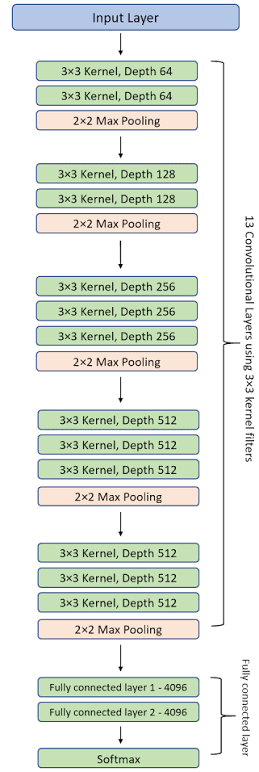

In [39]:
def build_cnn(input_shape=(224,224,3), num_classes=6):

    model = Sequential([

        Input(shape=input_shape),

        img_augmentation,

        layers.Rescaling(1./255),

        # Block 1
        Conv2D(64, (3,3), activation='relu', padding='same'),
        Conv2D(64, (3,3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2,2)),

        # Block 2
        Conv2D(128, (3,3), activation='relu', padding='same'),
        Conv2D(128, (3,3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2,2)),

        # Block 3
        Conv2D(256, (3,3), activation='relu', padding='same'),
        Conv2D(256, (3,3), activation='relu', padding='same'),
        Conv2D(256, (3,3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2,2)),

        # Block 4
        Conv2D(512, (3,3), activation='relu', padding='same'),
        Conv2D(512, (3,3), activation='relu', padding='same'),
        Conv2D(512, (3,3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2,2)),

        # Block 5
        Conv2D(512, (3,3), activation='relu', padding='same'),
        Conv2D(512, (3,3), activation='relu', padding='same'),
        Conv2D(512, (3,3), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(2,2)),

        # Fully Connected Layers
        Flatten(),

        Dense(4096, activation='relu'),
        
        Dense(4096, activation='relu'),

        Dense(num_classes, activation='softmax')
    ])
     # compile
    optimizer = optimizers.Adam(learning_rate = 1e-3)
    loss = losses.SparseCategoricalCrossentropy()
    model.compile(
        optimizer = optimizer, loss = loss, metrics = ['accuracy']
    )
    model.summary()
    return model

In [40]:
cnn = build_cnn()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ img_augmentation (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │        24,582 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,285,126 (512.26 MB)

 Trainable params: 134,285,126 (512.26 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
history = cnn.fit(
    train_ds,
    validation_data = validation_ds,
    callbacks = [lr_callback,stop_callback,model_ckpt],
    epochs = epochs,
    verbose =1
)

Epoch 1/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 95s 644ms/step - accuracy: 0.4123 - loss: 2.1822 - val_accuracy: 0.4335 - val_loss: 1.4083 - learning_rate: 0.0010
Epoch 2/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 76s 541ms/step - accuracy: 0.4195 - loss: 1.4368 - val_accuracy: 0.4335 - val_loss: 1.4031 - learning_rate: 0.0010
Epoch 3/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 75s 539ms/step - accuracy: 0.4195 - loss: 1.4357 - val_accuracy: 0.4335 - val_loss: 1.4052 - learning_rate: 0.0010
Epoch 4/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 75s 539ms/step - accuracy: 0.4195 - loss: 1.4341 - val_accuracy: 0.4335 - val_loss: 1.4049 - learning_rate: 0.0010
Epoch 5/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 76s 540ms/step - accuracy: 0.4195 - loss: 1.4337 - val_accuracy: 0.4335 - val_loss: 1.4047 - learning_rate: 0.0010
Epoch 6/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 75s 537ms/step - accuracy: 0.4195 - loss: 1.4334 - val_accuracy: 0.4335 - val_loss: 1.4044 - learning_rate: 0.0010
Epoch 7/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 75s 537ms/step - accura

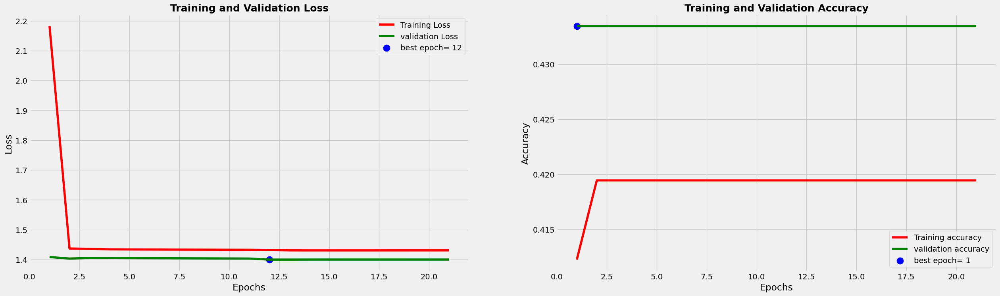

In [42]:
tr_acc   = history.history['accuracy']
tr_loss  = history.history['loss']
val_acc  = history.history['val_accuracy']
val_loss = history.history['val_loss']

idx_loss   = np.argmin(val_loss)
val_lowest = val_loss[idx_loss]
idx_acc    = np.argmax(val_acc)
val_highest= val_acc[idx_acc]

Epochs =[i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(idx_loss + 1)}'
acc_label = f'best epoch= {str(idx_acc + 1)}'


plt.figure(figsize=(28,8))
plt.style.use("fivethirtyeight")

plt.subplot(1,2,1)
plt.plot(Epochs,tr_loss,'r',label='Training Loss')
plt.plot(Epochs,val_loss,'g',label='validation Loss')
plt.scatter(idx_loss+1,val_lowest,s=150,c='blue',label= loss_label)
plt.title('Training and Validation Loss',fontweight='bold',fontsize=18)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(Epochs,tr_acc,'r',label='Training accuracy')
plt.plot(Epochs,val_acc,'g',label='validation accuracy')
plt.scatter(idx_acc+1,val_highest,s=150,c='blue',label= acc_label)
plt.title('Training and Validation Accuracy',fontweight='bold',fontsize=18)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


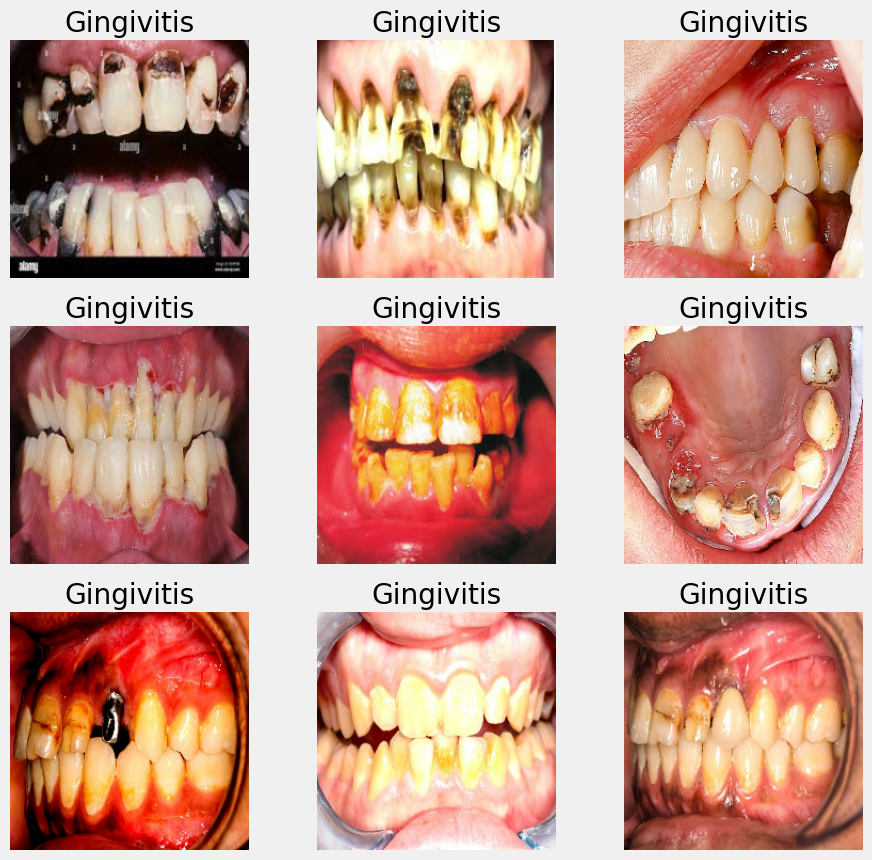

In [43]:
plt.figure(figsize=(10,10))
for images , labels in train_ds.take(1):
    for i in range(9):
        ax   = plt.subplot(3,3,i+1)
        pred = np.argmax(cnn.predict(np.array([images[i]])),axis =1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[pred[0]])
        plt.axis('off')

In [44]:
y_pred_probs = cnn.predict(validation_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

y_test = np.concatenate([labels.numpy() for _, labels in validation_ds], axis=0)

print("Shape of y_pred:", y_pred.shape)
print("Shape of y_test:", y_test.shape)

Shape of y_pred: (1112,)
Shape of y_test: (1112,)


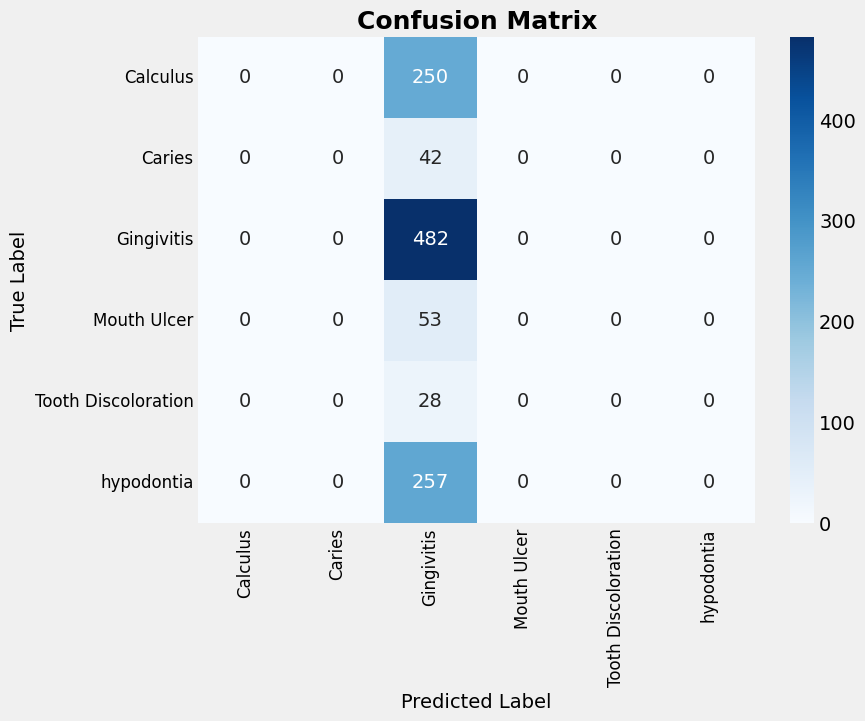

 Classification Report:

                     precision    recall  f1-score   support

           Calculus       0.00      0.00      0.00       250
             Caries       0.00      0.00      0.00        42
         Gingivitis       0.43      1.00      0.60       482
        Mouth Ulcer       0.00      0.00      0.00        53
Tooth Discoloration       0.00      0.00      0.00        28
         hypodontia       0.00      0.00      0.00       257

           accuracy                           0.43      1112
          macro avg       0.07      0.17      0.10      1112
       weighted avg       0.19      0.43      0.26      1112

 Accuracy Score: 0.4335


In [45]:
labels = list(range(len(class_names)))   # [0,1,2,3,4,5]

con = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))

sns.heatmap(con, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.title('Confusion Matrix', fontsize=18, weight='bold')
plt.xlabel('Predicted Label', fontsize=14)
plt.ylabel('True Label', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

print(" Classification Report:\n")
print(classification_report(
    y_test, y_pred,
    labels=labels,
    target_names=class_names,
    zero_division=0,
))
print(f" Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")

# EfficientNetB0

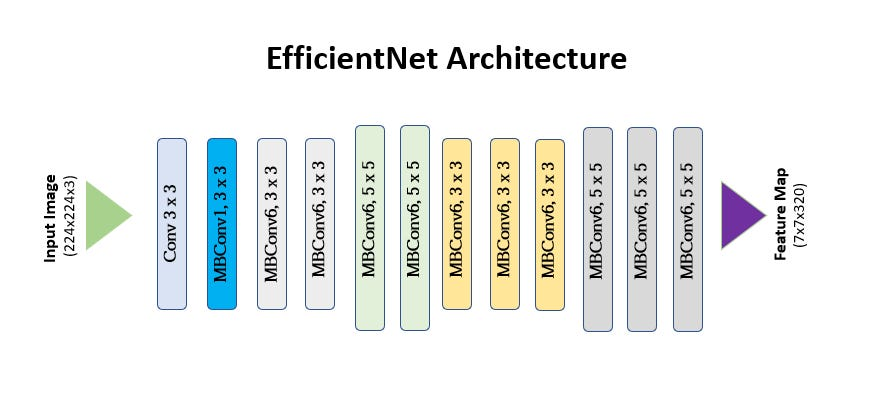

In [46]:
model_ckpt = callbacks.ModelCheckpoint("best_pretrained_EfficientNetB0_model.keras",save_best_only=True,monitor="val_accuracy",mode="max")

In [49]:
def build_EfficientNetB0(trainable_base=False):
    inputs = layers.Input(shape=(image_height, image_width, 3))
    x = img_augmentation(inputs)

    base_model = EfficientNetB0(
        include_top=False, weights='imagenet', input_tensor=x
    )
    base_model.trainable = trainable_base   

    # Rebuild top
    x = layers.GlobalAveragePooling2D(name='avg_pool')(base_model.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4, name='top_dropout')(x)
    outputs = layers.Dense(6, activation='softmax', name='pred')(x)

    model = tf.keras.Model(inputs, outputs, name='EfficientNetB0')

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss=losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy'],
    )
    model.summary()
    return model

In [50]:
model1 = build_EfficientNetB0()                

Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ img_augmentation    │ (None, 224, 224,  │          0 │ input_layer_7[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_4         │ (None, 224, 224,  │          0 │ img_augmentation… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_1     │ (None, 224, 224,  │          7 │ rescaling_4[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_5         │ (None, 224, 224,  │          0 │ normalization_1[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_5[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati

 Total params: 4,062,377 (15.50 MB)

 Trainable params: 10,246 (40.02 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [51]:
history = model1.fit(
    train_ds,
    validation_data = validation_ds,
    callbacks = [lr_callback,stop_callback,model_ckpt],
    epochs = epochs,
    verbose =1
)

Epoch 1/200


E0000 00:00:1793046623.204412      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 124ms/step - accuracy: 0.5237 - loss: 1.4317 - val_accuracy: 0.6960 - val_loss: 0.8022 - learning_rate: 0.0010
Epoch 2/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 101ms/step - accuracy: 0.6556 - loss: 0.9470 - val_accuracy: 0.7185 - val_loss: 0.6635 - learning_rate: 0.0010
Epoch 3/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 103ms/step - accuracy: 0.6783 - loss: 0.8491 - val_accuracy: 0.7482 - val_loss: 0.6199 - learning_rate: 0.0010
Epoch 4/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - accuracy: 0.7025 - loss: 0.7652 - val_accuracy: 0.7356 - val_loss: 0.6046 - learning_rate: 0.0010
Epoch 5/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.7151 - loss: 0.7262 - val_accuracy: 0.7482 - val_loss: 0.5858 - learning_rate: 0.0010
Epoch 6/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 98ms/step - accuracy: 0.7257 - loss: 0.6933 - val_accuracy: 0.7689 - val_loss: 0.5657 - learning_rate: 0.0010
Epoch 7/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 99ms/step - accuracy: 0.7259 - los

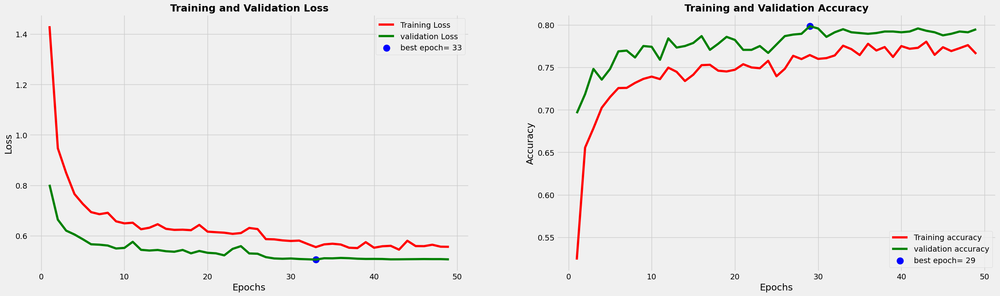

In [52]:
tr_acc   = history.history['accuracy']
tr_loss  = history.history['loss']
val_acc  = history.history['val_accuracy']
val_loss = history.history['val_loss']

idx_loss   = np.argmin(val_loss)
val_lowest = val_loss[idx_loss]
idx_acc    = np.argmax(val_acc)
val_highest= val_acc[idx_acc]

Epochs =[i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(idx_loss + 1)}'
acc_label = f'best epoch= {str(idx_acc + 1)}'


plt.figure(figsize=(28,8))
plt.style.use("fivethirtyeight")

plt.subplot(1,2,1)
plt.plot(Epochs,tr_loss,'r',label='Training Loss')
plt.plot(Epochs,val_loss,'g',label='validation Loss')
plt.scatter(idx_loss+1,val_lowest,s=150,c='blue',label= loss_label)
plt.title('Training and Validation Loss',fontweight='bold',fontsize=18)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(Epochs,tr_acc,'r',label='Training accuracy')
plt.plot(Epochs,val_acc,'g',label='validation accuracy')
plt.scatter(idx_acc+1,val_highest,s=150,c='blue',label= acc_label)
plt.title('Training and Validation Accuracy',fontweight='bold',fontsize=18)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


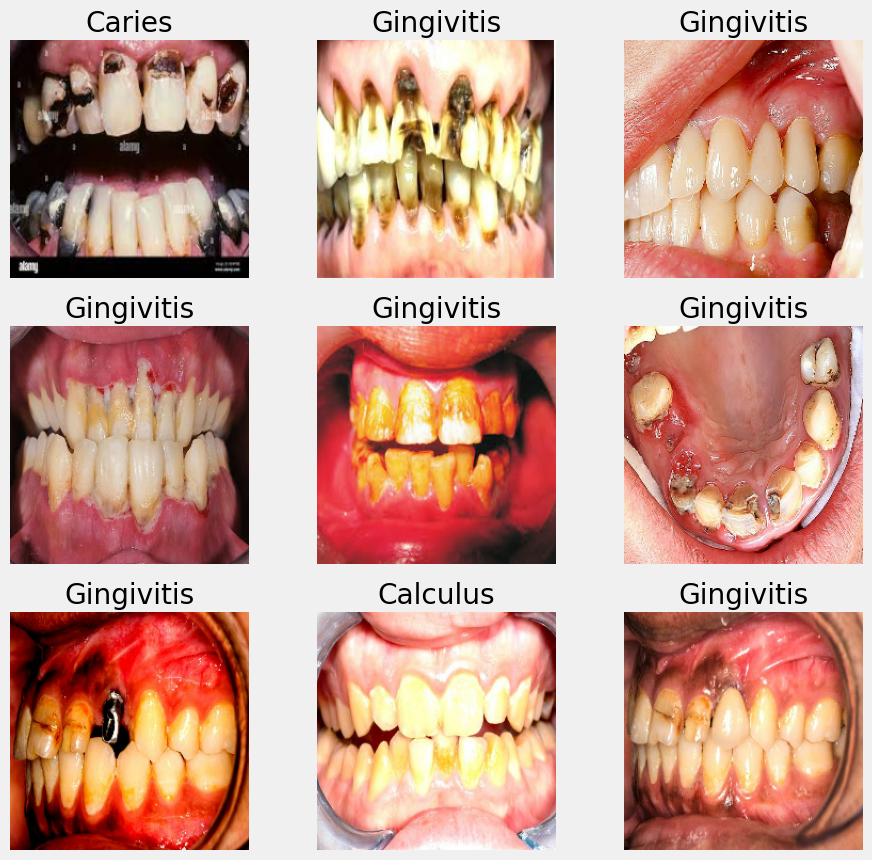

In [54]:
plt.figure(figsize=(10,10))
for images , labels in train_ds.take(1):
    for i in range(9):
        ax   = plt.subplot(3,3,i+1)
        pred = np.argmax(model1.predict(np.array([images[i]])),axis =1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[pred[0]])
        plt.axis('off')

In [56]:
y_pred_probs = model1.predict(validation_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

y_test = np.concatenate([labels.numpy() for _, labels in validation_ds], axis=0)

print("Shape of y_pred:", y_pred.shape)
print("Shape of y_test:", y_test.shape)

Shape of y_pred: (1112,)
Shape of y_test: (1112,)


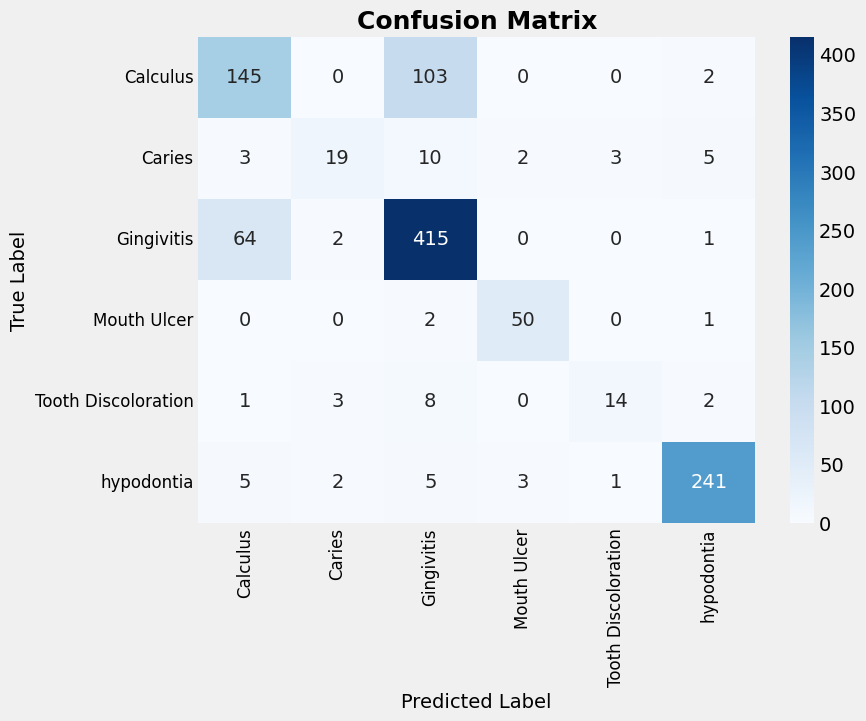

 Classification Report:

                     precision    recall  f1-score   support

           Calculus       0.67      0.58      0.62       250
             Caries       0.73      0.45      0.56        42
         Gingivitis       0.76      0.86      0.81       482
        Mouth Ulcer       0.91      0.94      0.93        53
Tooth Discoloration       0.78      0.50      0.61        28
         hypodontia       0.96      0.94      0.95       257

           accuracy                           0.79      1112
          macro avg       0.80      0.71      0.74      1112
       weighted avg       0.79      0.79      0.79      1112

 Accuracy Score: 0.7950


In [57]:
labels = list(range(len(class_names)))   # [0,1,2,3,4,5]

con = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))

sns.heatmap(con, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.title('Confusion Matrix', fontsize=18, weight='bold')
plt.xlabel('Predicted Label', fontsize=14)
plt.ylabel('True Label', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

print(" Classification Report:\n")
print(classification_report(
    y_test, y_pred,
    labels=labels,
    target_names=class_names,
    zero_division=0,
))
print(f" Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")

In [58]:
model_ckpt = callbacks.ModelCheckpoint("best_pretrained_unfreeze_EfficientNetB0_model.keras",save_best_only=True,monitor="val_accuracy",mode="max")

In [59]:
def unfreeze_EfficientNetB0_model(model, num_layers=20):
    for layer in model.layers[-num_layers:]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5), 
        loss=losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy'],
    )
    return model

In [61]:
model2 = unfreeze_EfficientNetB0_model(model1)     

In [62]:
history = model2.fit(
    train_ds,
    validation_data = validation_ds,
    callbacks = [lr_callback,stop_callback,model_ckpt],
    epochs = epochs,
    verbose =1
)

Epoch 1/200


E0000 00:00:1793047827.257605      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 127ms/step - accuracy: 0.7690 - loss: 0.5614 - val_accuracy: 0.7950 - val_loss: 0.5048 - learning_rate: 1.0000e-05
Epoch 2/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - accuracy: 0.7742 - loss: 0.5483 - val_accuracy: 0.7959 - val_loss: 0.5008 - learning_rate: 1.0000e-05
Epoch 3/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 100ms/step - accuracy: 0.7785 - loss: 0.5278 - val_accuracy: 0.7950 - val_loss: 0.4961 - learning_rate: 1.0000e-05
Epoch 4/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 103ms/step - accuracy: 0.7821 - loss: 0.5267 - val_accuracy: 0.8022 - val_loss: 0.4936 - learning_rate: 1.0000e-05
Epoch 5/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 99ms/step - accuracy: 0.7818 - loss: 0.5208 - val_accuracy: 0.8022 - val_loss: 0.4915 - learning_rate: 1.0000e-05
Epoch 6/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 99ms/step - accuracy: 0.7850 - loss: 0.5164 - val_accuracy: 0.7995 - val_loss: 0.4889 - learning_rate: 1.0000e-05
Epoch 7/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 100ms/ste

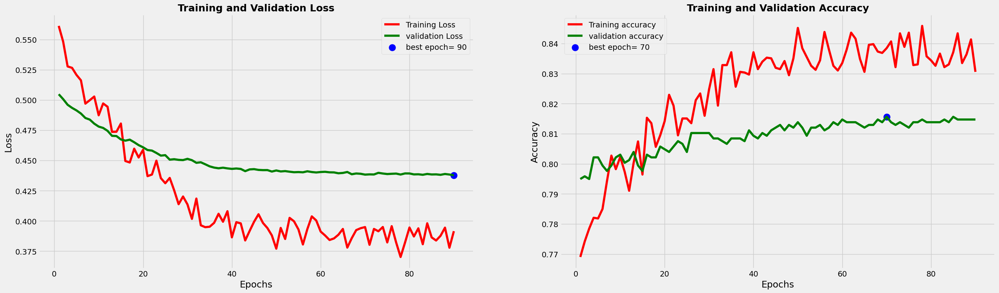

In [63]:
tr_acc   = history.history['accuracy']
tr_loss  = history.history['loss']
val_acc  = history.history['val_accuracy']
val_loss = history.history['val_loss']

idx_loss   = np.argmin(val_loss)
val_lowest = val_loss[idx_loss]
idx_acc    = np.argmax(val_acc)
val_highest= val_acc[idx_acc]

Epochs =[i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(idx_loss + 1)}'
acc_label = f'best epoch= {str(idx_acc + 1)}'


plt.figure(figsize=(28,8))
plt.style.use("fivethirtyeight")

plt.subplot(1,2,1)
plt.plot(Epochs,tr_loss,'r',label='Training Loss')
plt.plot(Epochs,val_loss,'g',label='validation Loss')
plt.scatter(idx_loss+1,val_lowest,s=150,c='blue',label= loss_label)
plt.title('Training and Validation Loss',fontweight='bold',fontsize=18)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(Epochs,tr_acc,'r',label='Training accuracy')
plt.plot(Epochs,val_acc,'g',label='validation accuracy')
plt.scatter(idx_acc+1,val_highest,s=150,c='blue',label= acc_label)
plt.title('Training and Validation Accuracy',fontweight='bold',fontsize=18)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


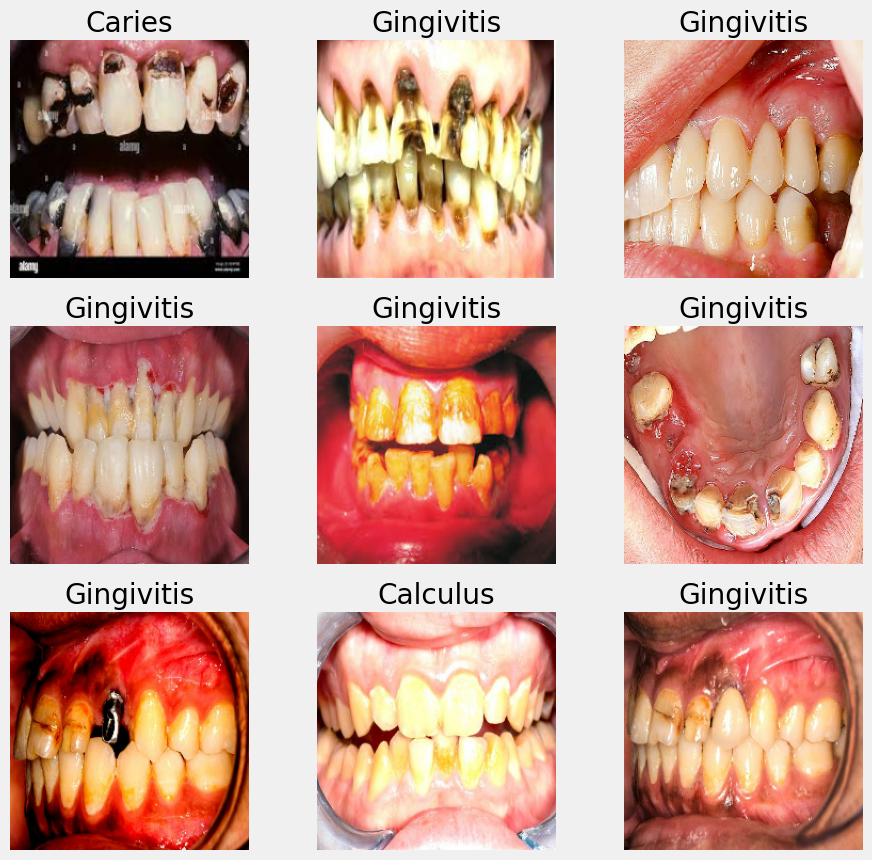

In [64]:
plt.figure(figsize=(10,10))
for images , labels in train_ds.take(1):
    for i in range(9):
        ax   = plt.subplot(3,3,i+1)
        pred = np.argmax(model2.predict(np.array([images[i]])),axis =1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[pred[0]])
        plt.axis('off')

In [65]:
y_pred_probs = model2.predict(validation_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

y_test = np.concatenate([labels.numpy() for _, labels in validation_ds], axis=0)

print("Shape of y_pred:", y_pred.shape)
print("Shape of y_test:", y_test.shape)

Shape of y_pred: (1112,)
Shape of y_test: (1112,)


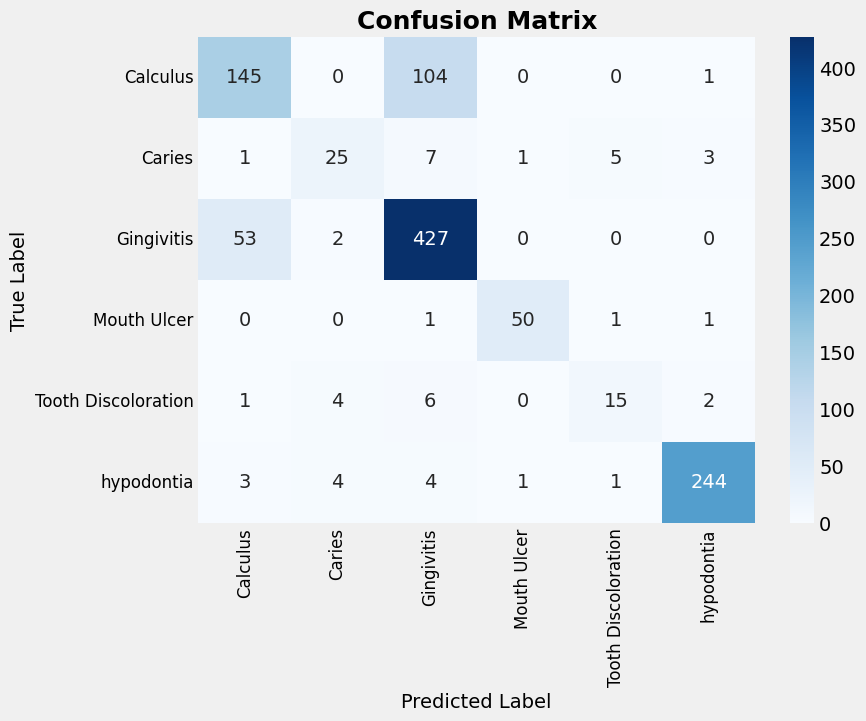

 Classification Report:

                     precision    recall  f1-score   support

           Calculus       0.71      0.58      0.64       250
             Caries       0.71      0.60      0.65        42
         Gingivitis       0.78      0.89      0.83       482
        Mouth Ulcer       0.96      0.94      0.95        53
Tooth Discoloration       0.68      0.54      0.60        28
         hypodontia       0.97      0.95      0.96       257

           accuracy                           0.81      1112
          macro avg       0.80      0.75      0.77      1112
       weighted avg       0.81      0.81      0.81      1112

 Accuracy Score: 0.8147


In [66]:
labels = list(range(len(class_names)))   # [0,1,2,3,4,5]

con = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))

sns.heatmap(con, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.title('Confusion Matrix', fontsize=18, weight='bold')
plt.xlabel('Predicted Label', fontsize=14)
plt.ylabel('True Label', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

print(" Classification Report:\n")
print(classification_report(
    y_test, y_pred,
    labels=labels,
    target_names=class_names,
    zero_division=0,
))
print(f" Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")

# ResNet50

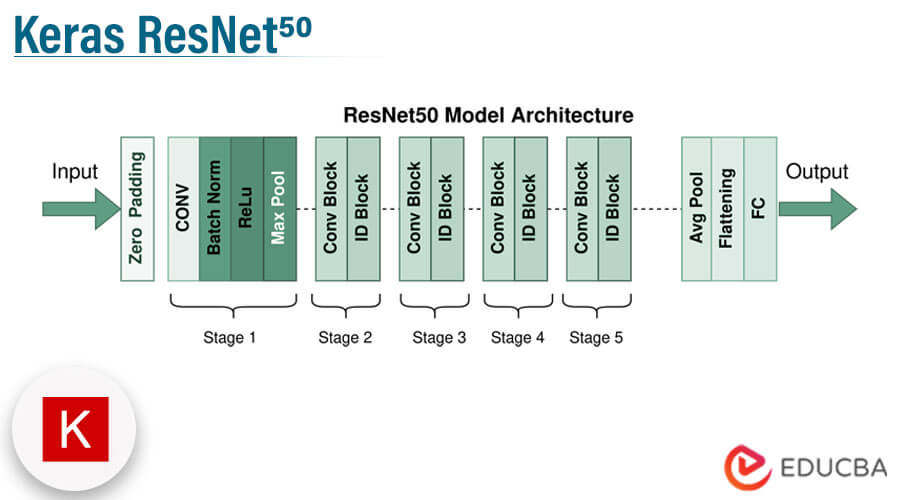

In [67]:
model_ckpt = callbacks.ModelCheckpoint("best_pretrained_ResNet50_model.keras",save_best_only=True,monitor="val_accuracy",mode="max")

In [68]:
def build_ResNet50(trainable_base=False):
    inputs = layers.Input(shape=(image_height, image_width, 3))
    x = img_augmentation(inputs)
    x = preprocess_input(x)

    base_model = ResNet50(
        include_top=False, weights='imagenet', input_tensor=x
    )
    base_model.trainable = trainable_base   

    # Rebuild top
    x = layers.GlobalAveragePooling2D(name='avg_pool')(base_model.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4, name='top_dropout')(x)
    outputs = layers.Dense(6, activation='softmax', name='pred')(x)

    model = tf.keras.Model(inputs, outputs, name='ResNet50')

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss=losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy'],
    )
    model.summary()
    return model

In [69]:
model3 = build_ResNet50() 

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ img_augmentation    │ (None, 224, 224,  │          0 │ input_layer_8[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ img_augmentation… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ img_augmentation… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ img_augmentation… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ add[0][0]         │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r

 Total params: 23,608,198 (90.06 MB)

 Trainable params: 16,390 (64.02 KB)

 Non-trainable params: 23,591,808 (90.00 MB)

In [70]:
history = model3.fit(
    train_ds,
    validation_data = validation_ds,
    callbacks = [lr_callback,stop_callback,model_ckpt],
    epochs = epochs,
    verbose =1
)

Epoch 1/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 204ms/step - accuracy: 0.5850 - loss: 1.2354 - val_accuracy: 0.7284 - val_loss: 0.6732 - learning_rate: 0.0010
Epoch 2/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 184ms/step - accuracy: 0.6843 - loss: 0.8866 - val_accuracy: 0.7275 - val_loss: 0.6556 - learning_rate: 0.0010
Epoch 3/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 179ms/step - accuracy: 0.7257 - loss: 0.7604 - val_accuracy: 0.7347 - val_loss: 0.6624 - learning_rate: 0.0010
Epoch 4/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 180ms/step - accuracy: 0.7351 - loss: 0.6959 - val_accuracy: 0.7383 - val_loss: 0.6186 - learning_rate: 0.0010
Epoch 5/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 183ms/step - accuracy: 0.7450 - loss: 0.6644 - val_accuracy: 0.7482 - val_loss: 0.6209 - learning_rate: 0.0010
Epoch 6/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.7567 - loss: 0.6324 - val_accuracy: 0.7545 - val_loss: 0.5890 - learning_rate: 0.0010
Epoch 7/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 24s 175ms/step - accura

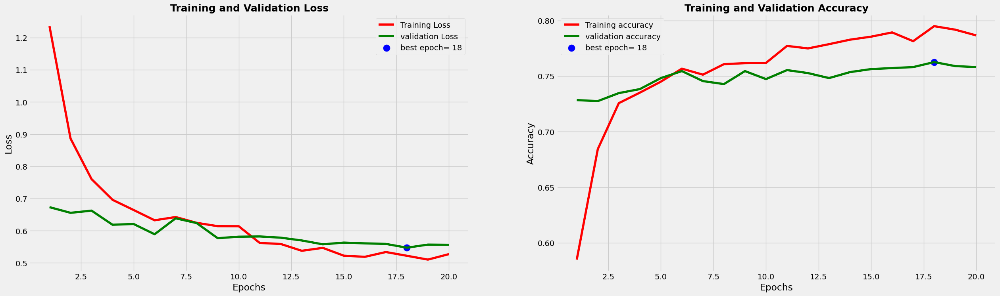

In [71]:
tr_acc   = history.history['accuracy']
tr_loss  = history.history['loss']
val_acc  = history.history['val_accuracy']
val_loss = history.history['val_loss']

idx_loss   = np.argmin(val_loss)
val_lowest = val_loss[idx_loss]
idx_acc    = np.argmax(val_acc)
val_highest = val_acc[idx_acc]

Epochs =[i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(idx_loss + 1)}'
acc_label = f'best epoch= {str(idx_acc + 1)}'


plt.figure(figsize=(28,8))
plt.style.use("fivethirtyeight")

plt.subplot(1,2,1)
plt.plot(Epochs,tr_loss,'r',label='Training Loss')
plt.plot(Epochs,val_loss,'g',label='validation Loss')
plt.scatter(idx_loss+1,val_lowest,s=150,c='blue',label= loss_label)
plt.title('Training and Validation Loss',fontweight='bold',fontsize=18)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(Epochs,tr_acc,'r',label='Training accuracy')
plt.plot(Epochs,val_acc,'g',label='validation accuracy')
plt.scatter(idx_acc+1,val_highest,s=150,c='blue',label= acc_label)
plt.title('Training and Validation Accuracy',fontweight='bold',fontsize=18)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


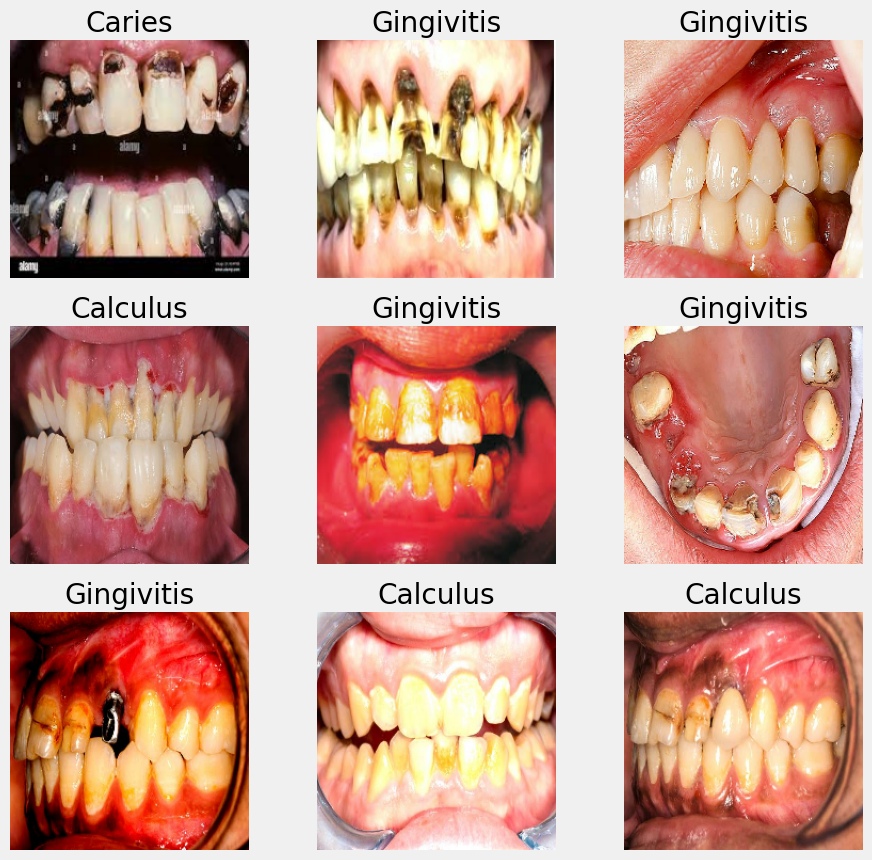

In [72]:
plt.figure(figsize=(10,10))
for images , labels in train_ds.take(1):
    for i in range(9):
        ax   = plt.subplot(3,3,i+1)
        pred = np.argmax(model3.predict(np.array([images[i]])),axis =1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[pred[0]])
        plt.axis('off')

In [73]:
y_pred_probs = model3.predict(validation_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

y_test = np.concatenate([labels.numpy() for _, labels in validation_ds], axis=0)

print("Shape of y_pred:", y_pred.shape)
print("Shape of y_test:", y_test.shape)

Shape of y_pred: (1112,)
Shape of y_test: (1112,)


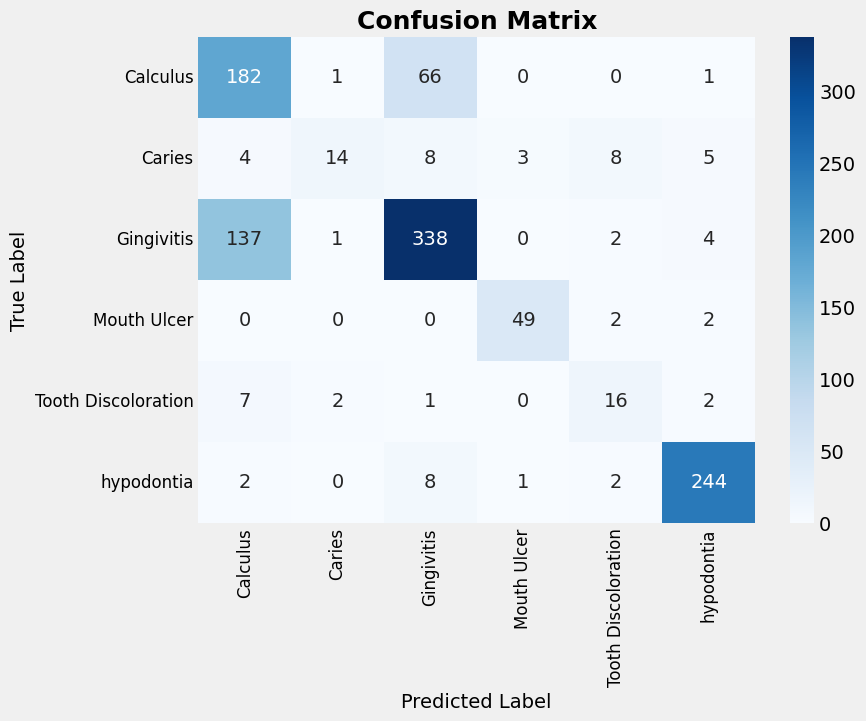

 Classification Report:

                     precision    recall  f1-score   support

           Calculus       0.55      0.73      0.63       250
             Caries       0.78      0.33      0.47        42
         Gingivitis       0.80      0.70      0.75       482
        Mouth Ulcer       0.92      0.92      0.92        53
Tooth Discoloration       0.53      0.57      0.55        28
         hypodontia       0.95      0.95      0.95       257

           accuracy                           0.76      1112
          macro avg       0.76      0.70      0.71      1112
       weighted avg       0.78      0.76      0.76      1112

 Accuracy Score: 0.7581


In [74]:
labels = list(range(len(class_names)))   # [0,1,2,3,4,5]

con = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))

sns.heatmap(con, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.title('Confusion Matrix', fontsize=18, weight='bold')
plt.xlabel('Predicted Label', fontsize=14)
plt.ylabel('True Label', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

print(" Classification Report:\n")
print(classification_report(
    y_test, y_pred,
    labels=labels,
    target_names=class_names,
    zero_division=0,
))
print(f" Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")

In [75]:
model_ckpt = callbacks.ModelCheckpoint("best_pretrained_unfreeze_ResNet50_model.keras",save_best_only=True,monitor="val_accuracy",mode="max")

In [78]:
def unfreeze_ResNet50_model(model, num_layers=25):
    for layer in model.layers[-num_layers:]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5), 
        loss=losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy'],
    )
    return model

In [80]:
model4 = unfreeze_ResNet50_model(model3)     

In [81]:
history = model4.fit(
    train_ds,
    validation_data = validation_ds,
    callbacks = [lr_callback,stop_callback,model_ckpt],
    epochs = epochs,
    verbose =1
)

Epoch 1/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 40s 224ms/step - accuracy: 0.7960 - loss: 0.5011 - val_accuracy: 0.7698 - val_loss: 0.5298 - learning_rate: 1.0000e-05
Epoch 2/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 209ms/step - accuracy: 0.7996 - loss: 0.4822 - val_accuracy: 0.7797 - val_loss: 0.5293 - learning_rate: 1.0000e-05
Epoch 3/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 197ms/step - accuracy: 0.8063 - loss: 0.4603 - val_accuracy: 0.7797 - val_loss: 0.5219 - learning_rate: 1.0000e-05
Epoch 4/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 207ms/step - accuracy: 0.8106 - loss: 0.4503 - val_accuracy: 0.7878 - val_loss: 0.4970 - learning_rate: 1.0000e-05
Epoch 5/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - accuracy: 0.8160 - loss: 0.4459 - val_accuracy: 0.7860 - val_loss: 0.5024 - learning_rate: 1.0000e-05
Epoch 6/200
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 205ms/step - accuracy: 0.8261 - loss: 0.4190 - val_accuracy: 0.7914 - val_loss: 0.4906 - learning_rate: 1.0000e-05
Epoch 7/200
140/140 ━━━━━━━━━━━━━━━━━━━━

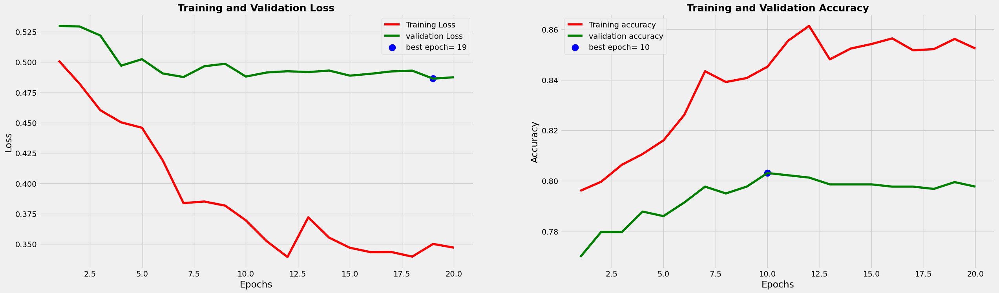

In [82]:
tr_acc   = history.history['accuracy']
tr_loss  = history.history['loss']
val_acc  = history.history['val_accuracy']
val_loss = history.history['val_loss']

idx_loss   = np.argmin(val_loss)
val_lowest = val_loss[idx_loss]
idx_acc    = np.argmax(val_acc)
val_highest= val_acc[idx_acc]

Epochs =[i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(idx_loss + 1)}'
acc_label = f'best epoch= {str(idx_acc + 1)}'


plt.figure(figsize=(28,8))
plt.style.use("fivethirtyeight")

plt.subplot(1,2,1)
plt.plot(Epochs,tr_loss,'r',label='Training Loss')
plt.plot(Epochs,val_loss,'g',label='validation Loss')
plt.scatter(idx_loss+1,val_lowest,s=150,c='blue',label= loss_label)
plt.title('Training and Validation Loss',fontweight='bold',fontsize=18)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(Epochs,tr_acc,'r',label='Training accuracy')
plt.plot(Epochs,val_acc,'g',label='validation accuracy')
plt.scatter(idx_acc+1,val_highest,s=150,c='blue',label= acc_label)
plt.title('Training and Validation Accuracy',fontweight='bold',fontsize=18)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


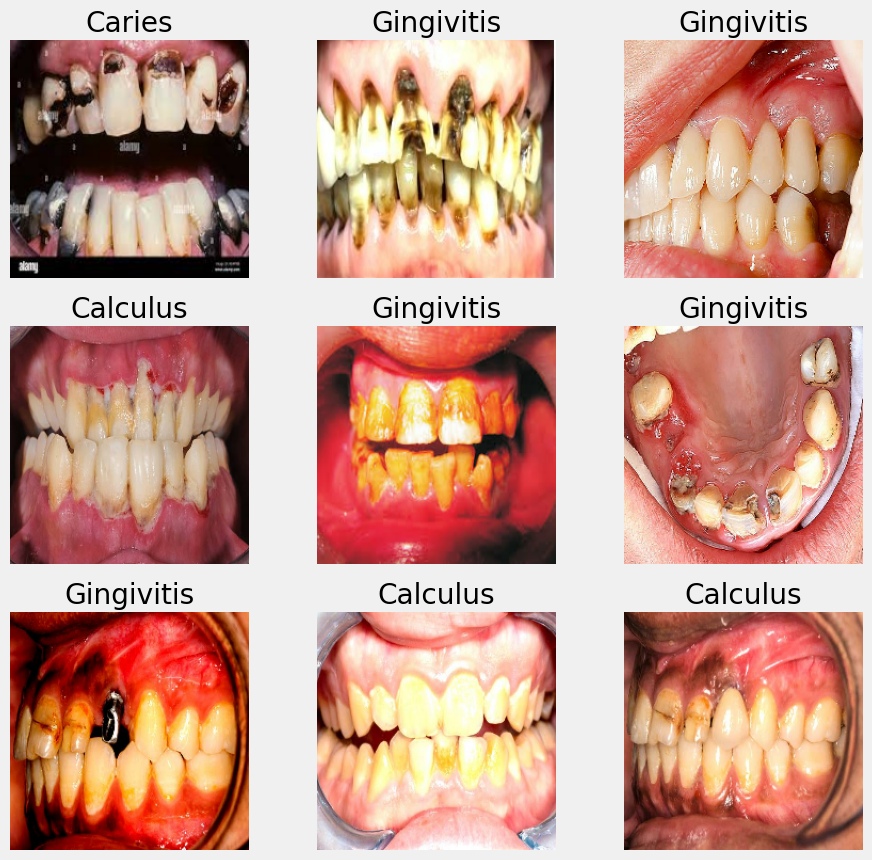

In [83]:
plt.figure(figsize=(10,10))
for images , labels in train_ds.take(1):
    for i in range(9):
        ax   = plt.subplot(3,3,i+1)
        pred = np.argmax(model4.predict(np.array([images[i]])),axis =1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[pred[0]])
        plt.axis('off')

In [84]:
y_pred_probs = model4.predict(validation_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

y_test = np.concatenate([labels.numpy() for _, labels in validation_ds], axis=0)

print("Shape of y_pred:", y_pred.shape)
print("Shape of y_test:", y_test.shape)

Shape of y_pred: (1112,)
Shape of y_test: (1112,)


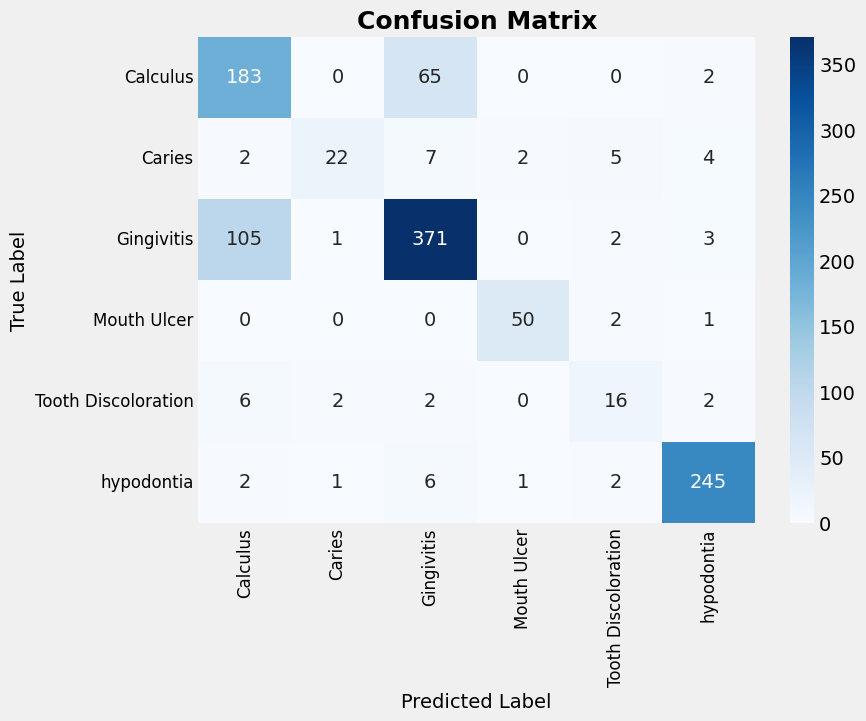

 Classification Report:

                     precision    recall  f1-score   support

           Calculus       0.61      0.73      0.67       250
             Caries       0.85      0.52      0.65        42
         Gingivitis       0.82      0.77      0.80       482
        Mouth Ulcer       0.94      0.94      0.94        53
Tooth Discoloration       0.59      0.57      0.58        28
         hypodontia       0.95      0.95      0.95       257

           accuracy                           0.80      1112
          macro avg       0.80      0.75      0.76      1112
       weighted avg       0.81      0.80      0.80      1112

 Accuracy Score: 0.7977


In [85]:
labels = list(range(len(class_names)))   # [0,1,2,3,4,5]

con = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))

sns.heatmap(con, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.title('Confusion Matrix', fontsize=18, weight='bold')
plt.xlabel('Predicted Label', fontsize=14)
plt.ylabel('True Label', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

print(" Classification Report:\n")
print(classification_report(
    y_test, y_pred,
    labels=labels,
    target_names=class_names,
    zero_division=0,
))
print(f" Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")

# Save Models

In [87]:
cnn.save("final_cnn.keras")
model1.save("final_EfficientNetB0.keras")
model2.save("final_unfreeze_EfficientNetB0.keras")
model3.save("final_ResNet50.keras")
model4.save("final_unfreeze_ResNet50.keras")